In [1]:
import random

import os

import warnings
warnings.filterwarnings('ignore')

from tqdm.notebook import tqdm

import numpy as np
import pandas as pd

from sklearn.datasets import make_classification
from sklearn.model_selection import KFold
from sklearn.metrics import roc_auc_score

import torch
import torch.nn as nn
from torch import optim
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torch.nn.functional import relu, sigmoid, softmax

import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
!pip install torchview


In [3]:
from torchview import draw_graph
import graphviz


In [4]:
DEVICE = 'cpu'

RS = 1000000
FS = 5


In [5]:
seed = 1723

random.seed(seed)
np.random.seed(seed)
os.environ['PYTHONHASHSEED'] = str(seed)

torch.manual_seed(seed)
torch.cuda.manual_seed(seed)
torch.use_deterministic_algorithms(mode=True)


In [6]:
## познакомимся с библиотекой pytorch, 
## тензорами, датасетом и лейерами, 
## форвард и бэкворд пасс 


In [7]:
x, y = make_classification(n_samples=10000)

feats_space = [f'feat{i}' for i in range(x.shape[1])]
df = pd.DataFrame(x, columns=feats_space)
df['label'] = y

df.head()


,feat0,feat1,feat2,feat3,feat4,feat5,feat6,feat7,feat8,feat9,...,feat11,feat12,feat13,feat14,feat15,feat16,feat17,feat18,feat19,label
0,0.202848,2.424447,-2.715042,-0.796075,-0.449191,-0.967904,-0.700035,-0.079470,2.583262,-1.408047,...,-0.139062,-0.338269,1.388218,0.651954,0.962307,-0.065145,-2.811095,2.381605,-1.455470,1
1,0.201649,1.861026,-1.960967,0.324692,0.666766,-0.257099,-1.127158,0.055825,0.018043,-0.923154,...,-1.713287,-0.186079,0.134590,0.973728,-1.476477,-0.931825,-0.434568,1.666065,-0.835975,1
2,1.487828,1.841981,-2.493505,1.403755,-0.484035,-0.199522,-0.507582,-0.682718,0.265587,-1.675383,...,0.939244,-0.514417,1.518163,-1.550831,0.589787,-1.025349,-1.495427,2.376452,-4.323110,1
3,-0.521002,-1.999434,-0.841941,-0.506114,-1.453225,-1.365199,-0.445697,0.758423,-0.033611,0.451167,...,-0.885480,-1.562278,0.101672,0.914394,-0.281590,-1.077845,0.924319,2.091681,1.513267,1
4,-0.016698,0.344846,1.558782,-0.504578,-0.375193,-1.575306,-0.375314,-1.758106,-1.027683,0.908492,...,-0.179510,1.114210,-1.222052,-0.573525,1.480825,-1.091688,1.200896,-2.221543,0.148764,0


In [8]:
class Dataset:

    def __init__(self, 
                 df, 
                 feats_space):
        self.df = df
        self.feats_space = feats_space

    def __len__(self):
        return self.df.shape[0]

    def __getitem__(self, 
                    idx):
        xs = torch.tensor(
            self.df.iloc[idx][self.feats_space], 
            dtype=torch.float32
        )
        ys = torch.tensor(
            self.df.iloc[idx]['label'], 
            dtype=torch.float32
        )

        return xs, ys

dataset = Dataset(df, 
                  feats_space)
dataloader = DataLoader(dataset, 
                        batch_size=8, 
                        shuffle=False, 
                        num_workers=0)

for xb, yb in dataloader:
    print (xb)
    print (yb)
    break


tensor([[ 0.2028,  2.4244, -2.7150, -0.7961, -0.4492, -0.9679, -0.7000, -0.0795,
          2.5833, -1.4080, -0.8017, -0.1391, -0.3383,  1.3882,  0.6520,  0.9623,
         -0.0651, -2.8111,  2.3816, -1.4555],
        [ 0.2016,  1.8610, -1.9610,  0.3247,  0.6668, -0.2571, -1.1272,  0.0558,
          0.0180, -0.9232,  0.1344, -1.7133, -0.1861,  0.1346,  0.9737, -1.4765,
         -0.9318, -0.4346,  1.6661, -0.8360],
        [ 1.4878,  1.8420, -2.4935,  1.4038, -0.4840, -0.1995, -0.5076, -0.6827,
          0.2656, -1.6754,  0.0570,  0.9392, -0.5144,  1.5182, -1.5508,  0.5898,
         -1.0253, -1.4954,  2.3765, -4.3231],
        [-0.5210, -1.9994, -0.8419, -0.5061, -1.4532, -1.3652, -0.4457,  0.7584,
         -0.0336,  0.4512,  0.8883, -0.8855, -1.5623,  0.1017,  0.9144, -0.2816,
         -1.0778,  0.9243,  2.0917,  1.5133],
        [-0.0167,  0.3448,  1.5588, -0.5046, -0.3752, -1.5753, -0.3753, -1.7581,
         -1.0277,  0.9085,  0.8166, -0.1795,  1.1142, -1.2221, -0.5735,  1.4808,
      

In [9]:
model = nn.Linear(len(feats_space), 5)
print (model.weight.shape, 
       model.bias.shape)
print (model.weight)
model.bias


torch.Size([5, 20]) torch.Size([5])
Parameter containing:
tensor([[-0.0724,  0.1713, -0.1546, -0.0890,  0.1323,  0.2125, -0.1322,  0.1758,
          0.1304, -0.1061, -0.1919,  0.1875, -0.1908, -0.0947, -0.2089, -0.2161,
         -0.1983,  0.0556,  0.1475,  0.0344],
        [-0.0844,  0.0520,  0.2046, -0.1645, -0.1120,  0.1825, -0.2083, -0.1183,
          0.1526, -0.1261,  0.1830,  0.2160,  0.1162,  0.1537, -0.1027, -0.0102,
          0.1319, -0.2235, -0.1557,  0.2183],
        [-0.1865, -0.1417,  0.1361, -0.0958,  0.0434, -0.0485,  0.0474,  0.0094,
          0.2153, -0.2047, -0.0519, -0.1724, -0.2085, -0.2055,  0.1476,  0.0744,
          0.0193, -0.0667, -0.0206,  0.1030],
        [-0.2187, -0.0120,  0.0771,  0.2200,  0.1221,  0.2179, -0.1223,  0.1232,
          0.0952,  0.1534,  0.1055, -0.1185,  0.1455, -0.2212,  0.1986,  0.0450,
          0.0849,  0.0143,  0.0074, -0.1487],
        [ 0.0790,  0.2056,  0.1991,  0.1015, -0.0555, -0.0015, -0.0873, -0.0748,
          0.1849, -0.0386,  0

Parameter containing:
tensor([-0.0823, -0.1594,  0.0992,  0.1187,  0.1576], requires_grad=True)

In [10]:
model(xb)


tensor([[ 0.9832, -0.0225,  0.2684, -0.5627,  0.6419],
        [ 0.9578, -1.2076, -0.0945,  0.3412, -0.3130],
        [ 1.0770, -1.0489, -1.5238, -0.7140,  0.0761],
        [-0.1068, -1.0836,  0.8589, -0.3506, -1.2652],
        [-1.6190,  0.0932, -0.0749, -0.0123,  1.0469],
        [ 1.3725, -0.8911, -0.5386,  0.0927, -0.3251],
        [ 0.8296, -0.8586, -1.6815, -1.4947, -0.6729],
        [ 1.3410, -1.1535,  0.0280, -0.3601, -0.6964]],
       grad_fn=<AddmmBackward0>)

In [11]:
class NeuralNet(nn.Module):
    
    def __init__(self, 
                 feats_space):
        super(NeuralNet, self).__init__()
        
        self.linear = nn.Linear(len(feats_space), 5)
        self.out = nn.Linear(5, 1)
    
    def forward(self, 
                x):
        
        h_linear = relu(self.linear(x))
        out = self.out(h_linear)
        
        return h_linear, out

model = NeuralNet(feats_space)

h_linear, out = model(xb)

print (h_linear)
out


tensor([[0.6639, 1.4731, 0.0000, 0.5939, 2.1243],
        [0.0000, 0.7150, 0.0000, 0.3299, 0.6859],
        [0.6375, 2.4333, 0.0000, 0.5100, 0.7235],
        [0.8836, 0.0000, 0.0000, 0.0000, 1.2388],
        [0.0000, 0.0000, 0.6502, 0.1308, 0.0000],
        [0.9159, 1.2499, 0.0000, 1.9033, 0.7320],
        [1.0744, 0.8932, 0.0000, 0.0000, 0.3105],
        [0.3796, 0.4990, 0.0000, 0.5970, 0.3919]], grad_fn=<ReluBackward0>)


tensor([[ 0.4797],
        [ 0.0845],
        [ 0.4377],
        [ 0.4820],
        [-0.0753],
        [-0.1401],
        [ 0.5322],
        [ 0.0431]], grad_fn=<AddmmBackward0>)

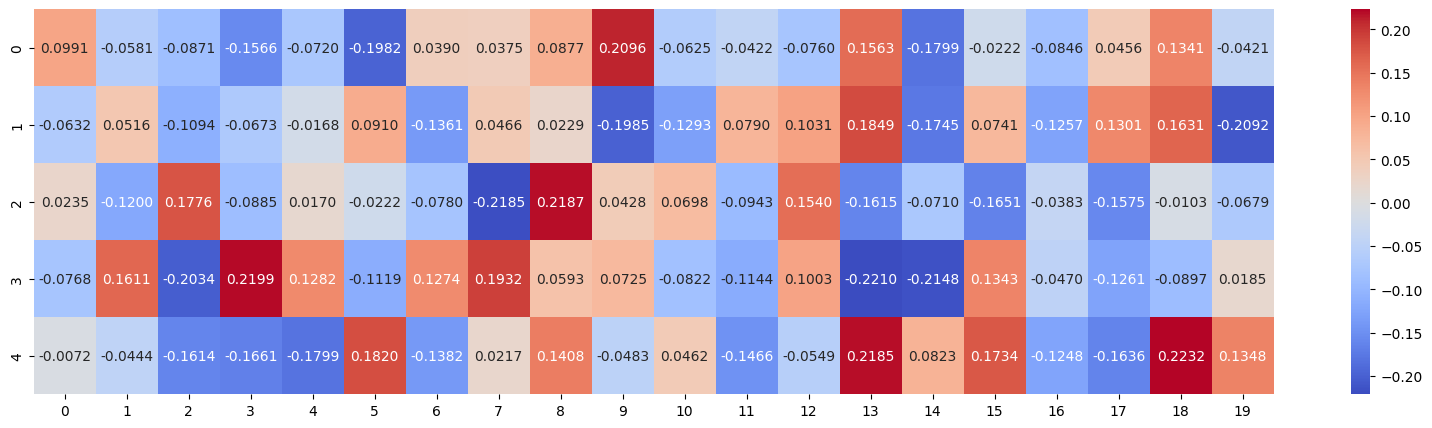

In [12]:
plt.figure(figsize=(20, 5))
sns.heatmap(
    model.linear.weight.detach().numpy(), 
    annot=True, 
    fmt=".4f", 
    cmap='coolwarm'
)
plt.show()


In [13]:
loss_fn = nn.BCEWithLogitsLoss()
loss = loss_fn(out.flatten(), 
               yb)
loss.backward()

loss


tensor(0.5835, grad_fn=<BinaryCrossEntropyWithLogitsBackward0>)

In [14]:
p = sigmoid(out).squeeze()
g = p - yb

g


tensor([-0.3823, -0.4789, -0.3923, -0.3818,  0.4812, -0.5350, -0.3700, -0.4892],
       grad_fn=<SubBackward0>)

In [15]:
h_linear


tensor([[0.6639, 1.4731, 0.0000, 0.5939, 2.1243],
        [0.0000, 0.7150, 0.0000, 0.3299, 0.6859],
        [0.6375, 2.4333, 0.0000, 0.5100, 0.7235],
        [0.8836, 0.0000, 0.0000, 0.0000, 1.2388],
        [0.0000, 0.0000, 0.6502, 0.1308, 0.0000],
        [0.9159, 1.2499, 0.0000, 1.9033, 0.7320],
        [1.0744, 0.8932, 0.0000, 0.0000, 0.3105],
        [0.3796, 0.4990, 0.0000, 0.5970, 0.3919]], grad_fn=<ReluBackward0>)

In [16]:
(g.unsqueeze(1) * h_linear).mean(dim=0, keepdim=True)


tensor([[-0.2393, -0.3879,  0.0391, -0.2291, -0.3245]],
       grad_fn=<MeanBackward1>)

In [17]:
model.out.weight.grad


tensor([[-0.2393, -0.3879,  0.0391, -0.2291, -0.3245]])

In [18]:
g = g.unsqueeze(1) * model.out.weight

g


tensor([[-0.1246, -0.0464,  0.0349,  0.1443, -0.0496],
        [-0.1561, -0.0581,  0.0437,  0.1808, -0.0621],
        [-0.1279, -0.0476,  0.0358,  0.1481, -0.0509],
        [-0.1244, -0.0463,  0.0348,  0.1441, -0.0495],
        [ 0.1568,  0.0584, -0.0439, -0.1817,  0.0624],
        [-0.1744, -0.0649,  0.0488,  0.2020, -0.0694],
        [-0.1206, -0.0449,  0.0337,  0.1397, -0.0480],
        [-0.1595, -0.0594,  0.0446,  0.1847, -0.0634]], grad_fn=<MulBackward0>)

In [19]:
mask = (h_linear > 0).float()
g = g * mask

g


tensor([[-0.1246, -0.0464,  0.0000,  0.1443, -0.0496],
        [-0.0000, -0.0581,  0.0000,  0.1808, -0.0621],
        [-0.1279, -0.0476,  0.0000,  0.1481, -0.0509],
        [-0.1244, -0.0000,  0.0000,  0.0000, -0.0495],
        [ 0.0000,  0.0000, -0.0439, -0.1817,  0.0000],
        [-0.1744, -0.0649,  0.0000,  0.2020, -0.0694],
        [-0.1206, -0.0449,  0.0000,  0.0000, -0.0480],
        [-0.1595, -0.0594,  0.0000,  0.1847, -0.0634]], grad_fn=<MulBackward0>)

In [20]:
g.t().matmul(xb) / xb.size(0)


tensor([[-8.4894e-03, -1.4054e-01,  2.1351e-01, -1.7763e-02,  2.2840e-02,
          8.8985e-02,  1.7873e-02, -1.0663e-02, -6.3766e-02,  3.0919e-02,
         -1.1745e-03,  3.9776e-03,  5.3151e-02, -8.2633e-02,  5.3456e-02,
          1.6155e-02,  1.0104e-01,  8.2138e-02, -2.1194e-01,  8.5712e-02],
        [-7.6411e-03, -7.7406e-02,  8.8844e-02, -1.1901e-02, -4.7543e-03,
          2.7087e-02,  1.2258e-02,  1.6540e-05, -2.4062e-02,  2.0826e-02,
          3.7301e-03,  8.7965e-03,  1.2091e-02, -3.1148e-02,  1.8121e-02,
          1.5106e-02,  3.8139e-02,  3.9083e-02, -7.8882e-02,  4.6738e-02],
        [ 9.1606e-05, -1.8919e-03, -8.5518e-03,  2.7682e-03,  2.0584e-03,
          8.6425e-03,  2.0591e-03,  9.6453e-03,  5.6381e-03, -4.9842e-03,
         -4.4800e-03,  9.8483e-04, -6.1128e-03,  6.7044e-03,  3.1465e-03,
         -8.1241e-03,  5.9892e-03, -6.5884e-03,  1.2188e-02, -8.1615e-04],
        [ 8.5923e-03,  1.9273e-01, -2.7395e-01,  4.8651e-02,  4.0686e-02,
         -3.5071e-02, -4.1187e-02, 

In [21]:
model.linear.weight.grad


tensor([[-8.4894e-03, -1.4054e-01,  2.1351e-01, -1.7763e-02,  2.2840e-02,
          8.8985e-02,  1.7873e-02, -1.0663e-02, -6.3766e-02,  3.0919e-02,
         -1.1745e-03,  3.9776e-03,  5.3151e-02, -8.2633e-02,  5.3456e-02,
          1.6155e-02,  1.0104e-01,  8.2138e-02, -2.1194e-01,  8.5712e-02],
        [-7.6411e-03, -7.7406e-02,  8.8844e-02, -1.1901e-02, -4.7543e-03,
          2.7087e-02,  1.2258e-02,  1.6540e-05, -2.4062e-02,  2.0826e-02,
          3.7301e-03,  8.7965e-03,  1.2091e-02, -3.1148e-02,  1.8121e-02,
          1.5106e-02,  3.8139e-02,  3.9083e-02, -7.8882e-02,  4.6738e-02],
        [ 9.1606e-05, -1.8919e-03, -8.5518e-03,  2.7682e-03,  2.0584e-03,
          8.6425e-03,  2.0591e-03,  9.6453e-03,  5.6381e-03, -4.9842e-03,
         -4.4800e-03,  9.8483e-04, -6.1128e-03,  6.7044e-03,  3.1465e-03,
         -8.1241e-03,  5.9892e-03, -6.5884e-03,  1.2188e-02, -8.1615e-04],
        [ 8.5923e-03,  1.9273e-01, -2.7395e-01,  4.8651e-02,  4.0686e-02,
         -3.5071e-02, -4.1187e-02, 

In [22]:
model.out.bias


Parameter containing:
tensor([0.0334], requires_grad=True)

In [23]:
model.out.bias.grad


tensor([-0.3185])

In [24]:
model.out.weight


Parameter containing:
tensor([[ 0.3259,  0.1213, -0.0912, -0.3775,  0.1297]], requires_grad=True)

In [25]:
optimizer = optim.SGD(model.parameters(), 
                      lr=.001, 
                      momentum=0.0)
optimizer.step()

model.out.weight


Parameter containing:
tensor([[ 0.3262,  0.1217, -0.0913, -0.3773,  0.1300]], requires_grad=True)

In [26]:
## задача и роль, аудитория -> страховая компания 

## соберём пайплайн для решения, 
## вкл сеть с двумя входами, 
## тренировчную петлю 


In [27]:
df = pd.read_csv('/kaggle/input/playground-series-s4e7/train.csv')

df = df.sample(RS)
df.reset_index(drop=True, 
               inplace=True)

print (df.isnull().any())
df.head()


id                      False
Gender                  False
Age                     False
Driving_License         False
Region_Code             False
Previously_Insured      False
Vehicle_Age             False
Vehicle_Damage          False
Annual_Premium          False
Policy_Sales_Channel    False
Vintage                 False
Response                False
dtype: bool


,id,Gender,Age,Driving_License,Region_Code,Previously_Insured,Vehicle_Age,Vehicle_Damage,Annual_Premium,Policy_Sales_Channel,Vintage,Response
0,4504043,Male,56,1,7.0,0,1-2 Year,Yes,33462.0,31.0,77,0
1,6888219,Male,61,1,28.0,0,1-2 Year,Yes,60739.0,124.0,205,1
2,6082001,Male,20,1,35.0,0,< 1 Year,Yes,40283.0,160.0,165,0
3,7835563,Male,25,1,28.0,1,< 1 Year,No,59823.0,152.0,288,0
4,3743545,Female,24,1,6.0,1,< 1 Year,No,27292.0,152.0,10,0


In [28]:
inds = []
kf = KFold(n_splits=FS, 
           shuffle=True, 
           random_state=1723)
for (train_index, valid_index) in kf.split(df):
    inds += [[train_index, valid_index]]


In [29]:
nums = [
    'Age', 
    'Annual_Premium', 
    'Vintage'
]
cats = [
    c for c in df.columns if c not in nums+['id', 'Response']
]

for c in tqdm(cats):
    df[c] = f'{c}_'+df[c].astype(str)

uni = set()
for c in tqdm(cats):
    uni = uni | set(df[c])

tokens = dict(zip(uni, 
                  range(len(uni))))
for i,k in enumerate(tokens):
    print (k, tokens[k])
    if i == 5:
        break

df.head()


  0%|          | 0/7 [00:00<?, ?it/s]

  0%|          | 0/7 [00:00<?, ?it/s]

Driving_License_1 0
Region_Code_39.0 1
Region_Code_10.0 2
Policy_Sales_Channel_107.0 3
Policy_Sales_Channel_14.0 4
Region_Code_11.0 5


,id,Gender,Age,Driving_License,Region_Code,Previously_Insured,Vehicle_Age,Vehicle_Damage,Annual_Premium,Policy_Sales_Channel,Vintage,Response
0,4504043,Gender_Male,56,Driving_License_1,Region_Code_7.0,Previously_Insured_0,Vehicle_Age_1-2 Year,Vehicle_Damage_Yes,33462.0,Policy_Sales_Channel_31.0,77,0
1,6888219,Gender_Male,61,Driving_License_1,Region_Code_28.0,Previously_Insured_0,Vehicle_Age_1-2 Year,Vehicle_Damage_Yes,60739.0,Policy_Sales_Channel_124.0,205,1
2,6082001,Gender_Male,20,Driving_License_1,Region_Code_35.0,Previously_Insured_0,Vehicle_Age_< 1 Year,Vehicle_Damage_Yes,40283.0,Policy_Sales_Channel_160.0,165,0
3,7835563,Gender_Male,25,Driving_License_1,Region_Code_28.0,Previously_Insured_1,Vehicle_Age_< 1 Year,Vehicle_Damage_No,59823.0,Policy_Sales_Channel_152.0,288,0
4,3743545,Gender_Female,24,Driving_License_1,Region_Code_6.0,Previously_Insured_1,Vehicle_Age_< 1 Year,Vehicle_Damage_No,27292.0,Policy_Sales_Channel_152.0,10,0


In [30]:
class Dataset:

    def __init__(self, 
                 df, 
                 nums, 
                 cats, 
                 tokens):
        self.df = df
        self.nums = nums
        self.cats = cats
        self.tokens = tokens

    def __len__(self):
        return self.df.shape[0]

    def __getitem__(self, 
                    idx):
        xs = {
            'nums': torch.tensor([self.df[num][idx] for num in self.nums], 
                                 dtype=torch.float32), 
            'cats': torch.tensor([self.tokens[self.df[cat][idx]] for cat in self.cats], 
                                 dtype=torch.int32)
        }
        ys = torch.tensor(self.df['Response'][idx], 
                          dtype=torch.float32)

        return xs, ys

dataset = Dataset(df, 
                  nums, 
                  cats, 
                  tokens)
dataloader = DataLoader(dataset, 
                        batch_size=1024, 
                        shuffle=True, 
                        num_workers=0)

for xb, yb in dataloader:
    print (len(xb['nums']))
    print (xb['nums'])
    print (xb['cats'])
    print (yb)
    break


1024
tensor([[2.7000e+01, 3.0117e+04, 2.1500e+02],
        [4.0000e+01, 3.2027e+04, 1.4900e+02],
        [4.6000e+01, 3.9091e+04, 2.0200e+02],
        ...,
        [6.1000e+01, 3.9259e+04, 1.1100e+02],
        [5.0000e+01, 2.8318e+04, 2.9600e+02],
        [5.2000e+01, 4.8682e+04, 4.9000e+01]])
tensor([[176,   0, 204,  ...,  41, 202, 147],
        [176,   0, 155,  ...,  53, 145, 200],
        [176,   0, 155,  ...,  53, 145, 163],
        ...,
        [176,   0, 155,  ...,  53, 145, 120],
        [176,   0, 180,  ...,  53, 145, 200],
        [176,   0, 155,  ...,  53, 145,  77]], dtype=torch.int32)
tensor([0., 0., 0.,  ..., 0., 0., 0.])


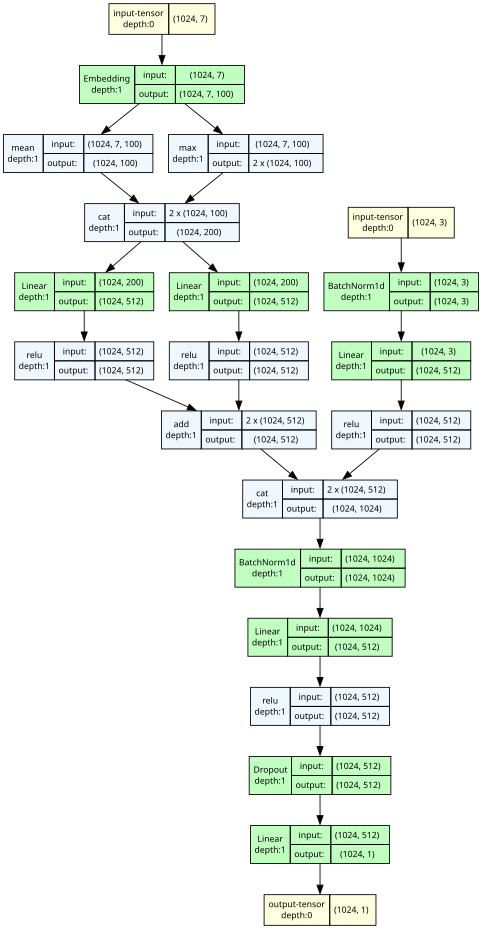

In [31]:
class NeuralNet(nn.Module):
    
    def __init__(self, 
                 n_nums, 
                 n_cats, 
                 evs_dim):
        super(NeuralNet, self).__init__()
        
        self.evs = nn.Embedding(evs_dim, 
                                100)
        
        self.linear1 = nn.Linear(100*2, 
                                 512)
        self.linear2 = nn.Linear(100*2, 
                                 512)
        
        self.bn3 = nn.BatchNorm1d(n_nums)
        self.linear3 = nn.Linear(n_nums, 
                                 512)
        
        self.bn4 = nn.BatchNorm1d(512*2)
        self.linear4 = nn.Linear(512*2, 
                                 512)
        self.dropout4 = nn.Dropout(0.2)
        
        self.out = nn.Linear(512, 1)
    
    def forward(self, 
                nums, 
                cats):
        
        h_evs = self.evs(cats)
        
        avg_pool = torch.mean(h_evs, 1)
        max_pool, _ = torch.max(h_evs, 1)
        h_concat = torch.cat((max_pool, 
                              avg_pool), 1)
        
        h_linear1  = relu(self.linear1(h_concat))
        h_linear2  = relu(self.linear2(h_concat))
        h_linear12 = h_linear1+h_linear2
        
        h_bn3 = self.bn3(nums)
        h_linear3  = relu(self.linear3(h_bn3))
        
        h_linear123 = torch.cat((h_linear12, 
                                 h_linear3), 1)
        
        h_bn4 = self.bn4(h_linear123)
        h_linear4  = relu(self.linear4(h_bn4))
        h_dropout4 = self.dropout4(h_linear4)
        
        out = self.out(h_dropout4)
        
        return out

model = NeuralNet(len(nums), 
                  len(cats), 
                  max(tokens.values())+1)
graph = draw_graph(model, 
                   input_data=(xb['nums'], xb['cats']), 
                   expand_nested=True)
graph.visual_graph


In [32]:
def training_phase(tra, 
                   val, 
                   fold, 
                   nums, 
                   cats, 
                   tokens):

    train_dataset = Dataset(tra, 
                            nums, 
                            cats, 
                            tokens)
    train_dataloader = DataLoader(train_dataset, 
                                  batch_size=1024, 
                                  shuffle=True, 
                                  num_workers=0)

    valid_dataset = Dataset(val, 
                            nums, 
                            cats, 
                            tokens)
    valid_dataloader = DataLoader(valid_dataset, 
                                  batch_size=1024, 
                                  shuffle=False, 
                                  num_workers=0)

    model = NeuralNet(len(nums), 
                      len(cats), 
                      max(tokens.values())+1)
    model.to(DEVICE)

    loss_fn = nn.BCEWithLogitsLoss()
    optimizer = optim.Adam(model.parameters())
    
    tr, best_ms = 0, 0
    for epoch in tqdm(range(32)):
        
        model.train()
        for xb, yb in train_dataloader:

            xb['nums'] = xb['nums'].to(DEVICE)
            xb['cats'] = xb['cats'].to(DEVICE)
            yb = yb.to(DEVICE)

            esti = torch.flatten(model(xb['nums'], 
                                       xb['cats']))

            loss = loss_fn(esti, yb)

            loss.backward()
            optimizer.step()
            optimizer.zero_grad()
        
        model.eval()
        valid_loss = 0
        estimations = []
        with torch.no_grad():
            for xb, yb in valid_dataloader:

                xb['nums'] = xb['nums'].to(DEVICE)
                xb['cats'] = xb['cats'].to(DEVICE)
                yb = yb.to(DEVICE)
                
                esti = torch.flatten(model(xb['nums'], 
                                           xb['cats']))
                estimations += sigmoid(esti).tolist()

                loss = loss_fn(esti, yb)
                valid_loss += loss.item() 

        valid_loss /= len(valid_dataloader)
        
        ms = roc_auc_score(val['Response'], 
                           estimations)
        print (f'epoch {epoch} statistics = [{valid_loss}, {ms}]')
        
        if ms > best_ms:
            torch.save(model.state_dict(), 
                       f'model{fold}.pth')
            best_ms = ms
            tr = 0
        else:
            tr += 1
            if tr == 4:
                break

    return best_ms

metrics = []

for fold in tqdm(range(FS)):
    
    tra = df.iloc[inds[fold][0]]
    tra.reset_index(drop=True, 
                    inplace=True)
    
    val = df.iloc[inds[fold][1]]
    val.reset_index(drop=True, 
                    inplace=True)
    
    metrics += [
        training_phase(tra, 
                       val, 
                       fold, 
                       nums, 
                       cats, 
                       tokens)
    ]

    print ('\n')

if len(metrics) > 1:
    print (metrics, np.mean(metrics), np.std(metrics))


  0%|          | 0/5 [00:00<?, ?it/s]

  0%|          | 0/32 [00:00<?, ?it/s]

epoch 0 statistics = [0.2648515516549957, 0.8607516150059191]
epoch 1 statistics = [0.26401809390102116, 0.8600246515044403]
epoch 2 statistics = [0.263774502262169, 0.8623977897325266]
epoch 3 statistics = [0.263101081534916, 0.8626917711446835]
epoch 4 statistics = [0.2631037023146542, 0.8623368360282487]
epoch 5 statistics = [0.2633211550359823, 0.8628541025956928]
epoch 6 statistics = [0.26285068219413565, 0.8635221469053957]
epoch 7 statistics = [0.2624606316034891, 0.8638845228176104]
epoch 8 statistics = [0.26272848514573915, 0.8634512093223061]
epoch 9 statistics = [0.26278563436804986, 0.8639998487590728]
epoch 10 statistics = [0.26237200352610374, 0.8639685336006981]
epoch 11 statistics = [0.26252631014403033, 0.8632588361550982]
epoch 12 statistics = [0.2620838030564542, 0.8642528328206158]
epoch 13 statistics = [0.2624349835879949, 0.863598807087658]
epoch 14 statistics = [0.26238666733308713, 0.8641773849138361]
epoch 15 statistics = [0.2616400038253288, 0.8646403842987554

  0%|          | 0/32 [00:00<?, ?it/s]

epoch 0 statistics = [0.2614032291636175, 0.8614412494269128]
epoch 1 statistics = [0.26184549486758757, 0.8624758050899832]
epoch 2 statistics = [0.26176123784816996, 0.8628144143553167]
epoch 3 statistics = [0.26029661898406187, 0.8636666128243697]
epoch 4 statistics = [0.2601165482584311, 0.8640852786161635]
epoch 5 statistics = [0.26031901771012617, 0.8637994873271302]
epoch 6 statistics = [0.2597800424056394, 0.8651093170806338]
epoch 7 statistics = [0.2602015460784338, 0.8638273848358883]
epoch 8 statistics = [0.2597141548687098, 0.8651602304133653]
epoch 9 statistics = [0.25984914007843757, 0.8654685840620352]
epoch 10 statistics = [0.2596217894128391, 0.8649300501188786]
epoch 11 statistics = [0.2596386322865681, 0.8655038274363296]
epoch 12 statistics = [0.2591121005920731, 0.8656307029303157]
epoch 13 statistics = [0.25915170955110567, 0.8658634282729725]
epoch 14 statistics = [0.25920496288002753, 0.8654549348555083]
epoch 15 statistics = [0.2589415019111974, 0.8659260328405

...

epoch 0 statistics = [0.2632609711465787, 0.860388250887825]
epoch 1 statistics = [0.26171876855042514, 0.8626271317532885]
epoch 2 statistics = [0.26285606759543323, 0.8623690856232844]
epoch 3 statistics = [0.2616138991196545, 0.8632515374964862]
epoch 4 statistics = [0.26224581441100764, 0.8635909834384583]
epoch 5 statistics = [0.2613382674753666, 0.8637029649039769]
epoch 6 statistics = [0.26169236513729, 0.8642823827610902]
epoch 7 statistics = [0.26076413295706924, 0.8647710674827942]
epoch 8 statistics = [0.2611032938774751, 0.8647712624120392]
epoch 9 statistics = [0.26107530485914676, 0.8644940159251341]
epoch 10 statistics = [0.26072039485585935, 0.865051134478894]
epoch 11 statistics = [0.2612262255683237, 0.8645755522918138]
epoch 12 statistics = [0.2605251090563073, 0.8647084173624315]
epoch 13 statistics = [0.26042525348614676, 0.8653612612324195]
epoch 14 statistics = [0.2607492772596223, 0.864965390860387]
epoch 15 statistics = [0.2606822998091883, 0.8647508101298802]


  0%|          | 0/32 [00:00<?, ?it/s]

epoch 0 statistics = [0.2631584738134121, 0.8617097672719327]
epoch 1 statistics = [0.2630022821225682, 0.8620454582582218]
epoch 2 statistics = [0.2630416061349061, 0.8617356881979519]
epoch 3 statistics = [0.2632181214890918, 0.863075343335757]
epoch 4 statistics = [0.26197268395703666, 0.8639838168518563]
epoch 5 statistics = [0.26229874675675313, 0.8638020278886306]
epoch 6 statistics = [0.26253749757092826, 0.8633398342875345]
epoch 7 statistics = [0.2614701363657202, 0.8645251508683947]
epoch 8 statistics = [0.26198109368584593, 0.8647403183265711]
epoch 9 statistics = [0.2623564817619567, 0.864046189277952]
epoch 10 statistics = [0.2618162853985417, 0.8648278818198227]
epoch 11 statistics = [0.26164349541068077, 0.8646762176085012]
epoch 12 statistics = [0.2618111838795701, 0.8646574221310949]
epoch 13 statistics = [0.26179435088926434, 0.864720689037217]
epoch 14 statistics = [0.2614899761214548, 0.8649463562173726]
epoch 15 statistics = [0.26277305170589565, 0.863576130814445]

  0%|          | 0/32 [00:00<?, ?it/s]

epoch 0 statistics = [0.2645443746325921, 0.8606400487112646]
epoch 1 statistics = [0.26353292311636767, 0.8623107548957566]
epoch 2 statistics = [0.2627539043219722, 0.8631406024422693]
epoch 3 statistics = [0.2627104821862007, 0.8636399723589747]
epoch 4 statistics = [0.26330014447472533, 0.8627055511157076]
epoch 5 statistics = [0.2638545985124549, 0.8633584109668837]
epoch 6 statistics = [0.26208711217860786, 0.8642897449215095]
epoch 7 statistics = [0.2618460803463751, 0.8647445510486463]
epoch 8 statistics = [0.26234933080113665, 0.8645639488093001]
epoch 9 statistics = [0.2624025844341638, 0.8647030763904641]
epoch 10 statistics = [0.262886430840103, 0.8643306973918718]
epoch 11 statistics = [0.2620706076980854, 0.8647748397849453]
epoch 12 statistics = [0.2624220141798866, 0.8647250159953938]
epoch 13 statistics = [0.26180251398865056, 0.8652114828975367]
epoch 14 statistics = [0.26178140010760753, 0.8652510717367152]
epoch 15 statistics = [0.26167467289737295, 0.86518303414196

In [33]:
## попробуйте сделать инд лейры для категорий (nn.embedding), 
## сравните метрики фолдов и теста 

## (домашнее задание) 


In [34]:
## попробуйте завести сеть в задачу рисков (home credit), 
## создайте ансамбль (grad boosting + deep learning) 

## (домашнее задание) 


In [35]:
## познакомимся с механизмом внимания,  
## broadcasting  


In [36]:
x = torch.randn(5, 4, 3)

x


tensor([[[ 0.1159, -0.9390,  1.1344],
         [ 1.0981, -2.2021,  2.0933],
         [-0.0771,  0.9906, -0.5244],
         [ 1.4893,  1.4166,  0.3486]],

        [[-0.1583,  0.1478, -0.4262],
         [-0.6778, -0.0239,  0.3375],
         [-2.5122,  0.7458,  1.3293],
         [-0.6524,  1.3170, -1.2633]],

        [[ 1.8942,  1.6520, -0.0889],
         [-0.6750,  0.3894,  0.8614],
         [ 1.7869, -0.3132, -0.5776],
         [-0.7746, -0.6951, -2.0935]],

        [[-1.6935, -1.0937,  1.1602],
         [-0.7597, -1.2929, -0.4478],
         [ 0.2798, -2.6220, -0.9822],
         [-0.6937, -0.1654,  0.0644]],

        [[ 0.7899,  1.7697, -0.1091],
         [-0.4941, -0.6431, -0.0819],
         [ 0.5866,  0.9126, -0.1404],
         [ 0.9080, -0.2286,  1.1406]]])

In [37]:
class TimeAttention(nn.Module):
    
    def __init__(self, 
                 steps):
        super().__init__()
        
        self.weights = nn.Parameter(torch.zeros(steps))

    def forward(self, 
                x):
        
        am = softmax(self.weights, dim=0)
        am = am.view(1, -1, 1)
        x = x * am
        
        x = x.sum(dim=1)

        return x

attention_mechanism = TimeAttention(4)
attention_mechanism(x)


tensor([[ 0.6566, -0.1835,  0.7630],
        [-1.0002,  0.5467, -0.0057],
        [ 0.5579,  0.2583, -0.4747],
        [-0.7168, -1.2935, -0.0514],
        [ 0.4476,  0.4527,  0.2023]], grad_fn=<SumBackward1>)

In [38]:
attention_mechanism.weights


Parameter containing:
tensor([0., 0., 0., 0.], requires_grad=True)

In [39]:
class TimeAttention(nn.Module):
    
    def __init__(self, 
                 steps, 
                 input_dim):
        super().__init__()
        self.weights = nn.Parameter(torch.zeros(steps))
        self.linear = nn.Linear(input_dim, input_dim)  

    def forward(self, 
                x):

        x = self.linear(x) 

        am = softmax(self.weights, dim=0)
        am = am.view(1, -1, 1)
        x = x * am  
        
        x = x.sum(dim=1)  

        return x

attention_mechanism = TimeAttention(4,3)
attention_mechanism(x)


tensor([[-0.5750, -0.4168,  0.3525],
        [-0.1169, -0.5282, -0.0470],
        [-0.5862, -0.8232, -0.2040],
        [ 0.4763, -0.2695,  0.3486],
        [-0.6807, -0.6520,  0.0058]], grad_fn=<SumBackward1>)

In [40]:
## попробуйте вкл attention layer в модель (home credit), 
## сохранить сигнал в аггрегации (инд веса вместо стат)

## (домашнее задание) 
